In [2]:
##Josie Pettis##
#Assignment 3: NOV 20, 2026

"""
Created By    : Jared W. Marquis
Creation Date : 01 August 2022
Course        : ATSC 528 - Atmospheric Data Analysis
Assignment    : #03 - Statistical Objective Analysis

Purpose:
Script to take sparse upper air observations and analyze them on a
polar stereographic map projection using statistical objective analysis.
[PUT MORE INFORMATION HERE - I.E., WHAT SPECIFIC THING IS BEING DONE]

"""
__author__   ="Jared W. Marquis"
__contact__  ="jared.marquis@und.edu"

In [3]:
### Import Required Modules (shouldn't need to change) ###
import numpy as np                 #numpy for math
import matplotlib.pyplot as plt    #matplotlib for plotting
import cartopy.crs as ccrs         #cartopy for plotting on map
import cartopy.feature as cfeature #cartopy basic shapefiles
import pandas as pd

In [4]:
### Read in observations ###
name=['Station ID','Latitude','Longitude','500mb Height (m)','500mb Wind Direction','500mb Wind Speed (kt)'] #create column names
df=pd.read_csv('RAOBs_201903131200.txt',sep=',',header=None,names=name) #i am utilizing Pandas to read in the text file,so I added it to the Modules.
df=df.dropna().reset_index(drop=True) #Obtained via Claude (Talked to Jared about this, since his data had NaNs) This line helped remove
#the NA or NaN in data file read in

#Knowns
phi_0=np.radians(60)
lambda_0=-100
m=1/15000000
rho=6371*1e3 #calculate via SI units

In [5]:
### Set up analysis map with a 21x27 rectangular grid of points ###

#from assignment 2
mX,mY=21,27 # x (N to S) and y (W to E)
dx=dy=1.27 #cm
xo,yo=25,-15.5 #cm

#x increases to the south y increases eastward.
x_fix=xo+dx*np.arange(mX)
y_fix=yo+dy*np.arange(mY)
x_cm,y_cm=np.meshgrid(x_fix,y_fix,indexing='ij')   #shape 21x27

x=x_cm/100.0/m   #map cm onto image plane
y=y_cm /100.0/m
psi0=np.pi/2-phi_0  #co-latitude
r=np.sqrt(x**2+y**2) #calculate using distance eqn
phi=np.pi/2-2.0*np.arctan(r/(rho*(1.0+np.cos(psi0)))) #from the notes
lam=np.arctan2(y,x) #lambda=lon-lam0 (east positive)
lat=np.degrees(phi)
lon=(lambda_0+np.degrees(lam)+180.0)%360.0-180.0

In [6]:
### convert obs lat/long to x,y ###
phi=np.radians(df['Latitude'].values)
lam=np.radians(df['Longitude'].values-lambda_0) #east positive
sigma=(1.0+np.sin(phi_0))/(1.0+np.sin(phi)) #calculating sigma/scale factor
R=m*sigma*rho*np.cos(phi) #creates radius of lat circle found in notes
df['x_cm']=100.0*R*np.cos(lam) #x should theoretically increases southward IN CENTIMETERS
df['y_cm']=100.0*R*np.sin(lam) #y should theoretically increases eastward IN CENTIMETERS

In [7]:
### Background field: one-pass Barnes analysis, then background at each observation location ###
obs_x=df['x_cm'].values #observation locations cm
obs_y=df['y_cm'].values
obs_z=df['500mb Height (m)'].values #observed 500mb heights m
n_obs=len(obs_x) #number of stations (135)

X,Y=x_cm,y_cm #analysis grid cm
nx,ny=X.shape #21x27

Kd=10.8844524 #Barnes weight parameter cm^2
re=12.7775892 #radius of influence cm

#background field fB: w=exp(-dik^2/Kd) for dik<=re, otherwise 0
fB=np.full((nx,ny),np.nan)
for i in range(nx):
    for j in range(ny):
        d=np.sqrt((obs_x-X[i,j])**2+(obs_y-Y[i,j])**2) #grid point to every station
        w=np.where(d<=re,np.exp(-d**2/Kd),0.0)
        wsum=w.sum()
        if wsum==0:
            continue #no station within re, leave NaN
        fB[i,j]=(w*obs_z).sum()/wsum

#grid indices of each station
df['i']=(df['x_cm']-xo)/dx
df['j']=(df['y_cm']-yo)/dy
i_obs=df['i'].values
j_obs=df['j'].values

#background at each station use bilinear inside the grid or Barnes if fB outside it
fB_at_obs=np.full(n_obs,np.nan)
for k in range(n_obs): #This loop gets the matrix required in the assignment
    i0=int(np.floor(i_obs[k]))
    j0=int(np.floor(j_obs[k]))
    if i0>=0 and j0>=0 and i0+1<=nx-1 and j0+1<=ny-1:
        di=i_obs[k]-i0
        dj=j_obs[k]-j0
        fB_at_obs[k]=(fB[i0,j0]*(1-di)*(1-dj)+fB[i0+1,j0]*di*(1-dj)+fB[i0,j0+1]*(1-di)*dj+fB[i0+1,j0+1]*di*dj)
    else:
        d=np.sqrt((X.ravel()-obs_x[k])**2+(Y.ravel()-obs_y[k])**2)
        w=np.where(d<=re,np.exp(-d**2/Kd),0.0)
        wsum=w.sum()
        if wsum!=0:
            fB_at_obs[k]=(w*fB.ravel()).sum()/wsum #otherwise stays NaN

In [8]:
#Statistical interpolation using the N=2,4,10 closest stations, plus analysis error
#Schlatter rho(s)=0.95*exp(-1.24*s^2), s=distance on the Earth in 1000s of km
sigma40=(1.0+np.sin(phi_0))/(1.0+np.sin(np.radians(40))) #image scale factor for 40
cm_per_1000km=100.0*m*sigma40*1e6 #grid cm to 1000 km on the Earth
b=1.24 #range factor for s in 1000s of km

N_list=[2,4,10] #number of closest stations used

valid=np.isfinite(fB_at_obs) #stations that have a background value
sx=obs_x[valid]
sy=obs_y[valid]
innov=obs_z[valid]-fB_at_obs[valid] #Ok-Bk

#This will be our value we are plotting
fA=np.full((nx,ny,len(N_list)),np.nan) #analysis, one (nxxny) field per N
eA2=np.full((nx,ny,len(N_list)),np.nan) #error variance E_A^2/E_B^2
for n,N in enumerate(N_list):
    for i in range(nx):
        for j in range(ny):
            if np.isnan(fB[i,j]):
                continue
            d_gp=np.sqrt((sx-X[i,j])**2+(sy-Y[i,j])**2) #grid point i to every station cm
            near=np.argsort(d_gp)[:N] #the N closest stations
            xk=sx[near]
            yk=sy[near]
            #rho_kl is correlation between every pair of the N stations
            s_kl=np.sqrt((xk[:,None]-xk[None,:])**2+(yk[:,None]-yk[None,:])**2)/cm_per_1000km
            rho_kl=np.where(s_kl==0,1.0,0.95*np.exp(-b*s_kl**2))
            #rho_ki is correlation between each of the N stations and grid point i
            s_ki=d_gp[near]/cm_per_1000km
            rho_ki=np.where(s_ki==0,1.0,0.95*np.exp(-b*s_ki**2))
            w_ik=np.linalg.solve(rho_kl,rho_ki) #sum_l w_ik*rho_kl=rho_ik
            fA[i,j,n]=fB[i,j]+(w_ik*innov[near]).sum() #A_i=B_i+sum W_ik(O_k-B_k)
            eA2[i,j,n]=1.0-(w_ik*rho_ki).sum() #E_A^2/E_B^2=1-sum of rho_ki*W_ik (perfect obs)

In [9]:
#Forward interpolation of each analysis to the stations
fA_at_obs=np.full((n_obs,len(N_list)),np.nan) #analysis value at each station, one column per N
for n in range(len(N_list)):
    for k in range(n_obs):
        i0=int(np.floor(i_obs[k]))
        j0=int(np.floor(j_obs[k]))
        if i0>=0 and j0>=0 and i0+1<=nx-1 and j0+1<=ny-1:
#station inside the grid bilinear interpolation of the 4 surrounding grid points
            di=i_obs[k]-i0
            dj=j_obs[k]-j0
            fA_at_obs[k,n]=(fA[i0,j0,n]*(1-di)*(1-dj)+fA[i0+1,j0,n]*di*(1-dj)+fA[i0,j0+1,n]*(1-di)*dj+fA[i0+1,j0+1,n]*di*dj)
        else:
#station outside the grid Barnes weighting of the GRID values of the analysis
            d=np.sqrt((X.ravel()-obs_x[k])**2+(Y.ravel()-obs_y[k])**2)
            w=np.where(d<=re,np.exp(-d**2/Kd),0.0)
            wsum=w.sum()
            if wsum!=0:
                fA_at_obs[k,n]=(w*fA[:,:,n].ravel()).sum()/wsum #if not then it stays NaN

diff_at_obs=fA_at_obs-obs_z[:,None] #analysis value minus observation value at each station

In [10]:
#Calculate RMS differences
K_N2=np.sum(np.isfinite(fA_at_obs[:,0])) #number of obs with a valid analysis value
K_N4=np.sum(np.isfinite(fA_at_obs[:,1]))
K_N10=np.sum(np.isfinite(fA_at_obs[:,2]))

#Using a similar formula from the last assignment but use the different K values of each N value
rms_N2=np.sqrt(np.nansum((obs_z-fA_at_obs[:,0])**2)/K_N2)
rms_N4=np.sqrt(np.nansum((obs_z-fA_at_obs[:,1])**2)/K_N4)
rms_N10=np.sqrt(np.nansum((obs_z-fA_at_obs[:,2])**2)/K_N10)

print("N=2",rms_N2)
print("N=4",rms_N4)
print("N=10",rms_N10)

N=2 63.20586309181361
N=4 60.407657023022885
N=10 62.265397105466285


In [11]:
#Analysis increment fields (analysis minus background)
fInc=np.full((nx,ny,len(N_list)),np.nan) #increment fields, one per N
for n in range(len(N_list)):
    fInc[:,:,n]=fA[:,:,n]-fB #Analysis-obs at every grid point

#Print raw analysis first row and increment ranges
for n,N in enumerate(N_list):
    print(f"N={N}")
    print("analysis first row",np.round(fA[0,:5,n],2))
    print(f"increment range {np.nanmin(fInc[:,:,n])} to {np.nanmax(fInc[:,:,n])} m")

N=2
analysis first row [5476.85 5474.18 5466.4  5431.92 5395.81]
increment range -116.22589829951539 to 55.10978684450947 m
N=4
analysis first row [5488.25 5476.77 5456.9  5428.7  5397.87]
increment range -97.01850043711056 to 65.00362245960241 m
N=10
analysis first row [5492.26 5484.94 5459.73 5429.38 5403.21]
increment range -79.67104674811253 to 82.1433765591546 m


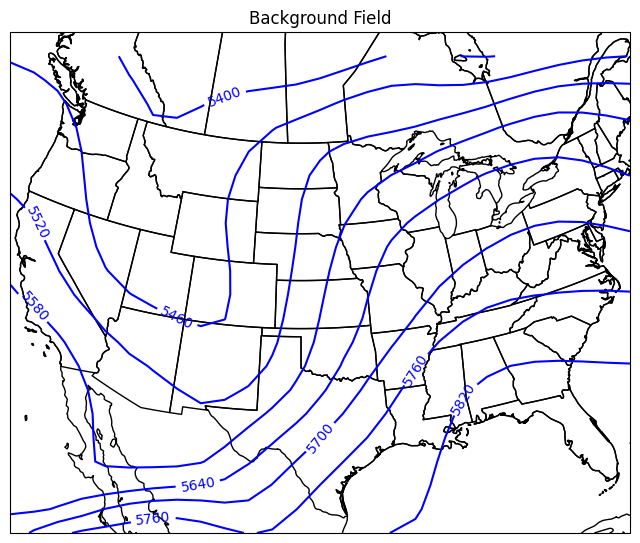

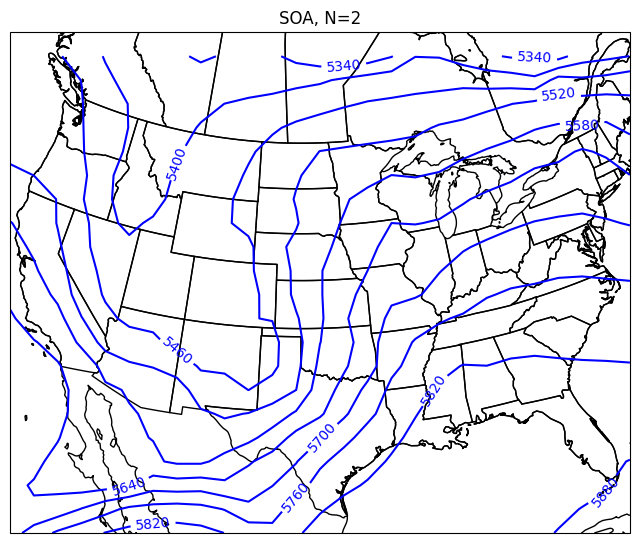

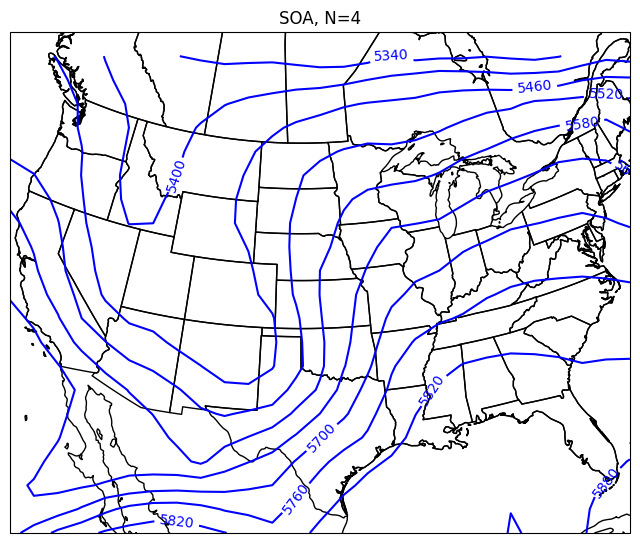

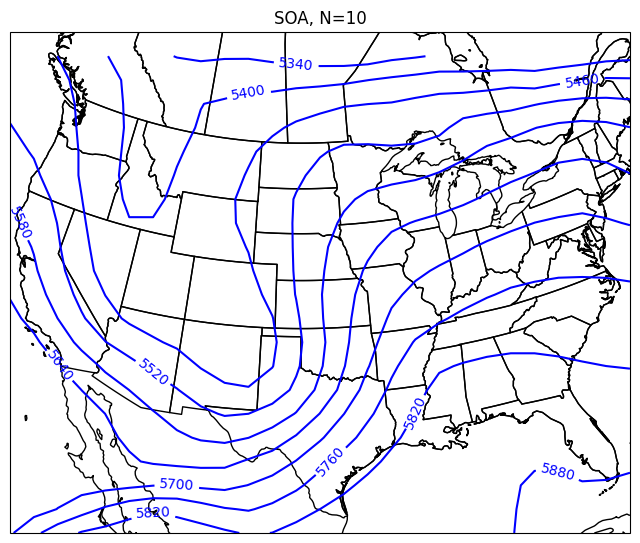

In [12]:
#Plot the analyses
globe=ccrs.Globe(ellipse=None,semimajor_axis=rho,semiminor_axis=rho)
proj=ccrs.Stereographic(central_longitude=lambda_0,central_latitude=90,true_scale_latitude=np.degrees(phi_0),globe=globe)

fig=plt.figure(figsize=(8,8))
ax=fig.add_subplot(111,projection=proj)
ax.add_feature(cfeature.STATES)
ax.add_feature(cfeature.COASTLINE)
cs=ax.contour(lon,lat,fB,colors='b',levels=np.arange(0,8000,60),transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs,levels=np.arange(0,8000,60))
ax.set_title('Background Field')
plt.savefig('background_barnes.png')
plt.show()

#Analysis N=2
fig=plt.figure(figsize=(8,8))
ax1=fig.add_subplot(111,projection=proj)
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)
cs1=ax1.contour(lon,lat,fA[:,:,0],colors='b',levels=np.arange(0,8000,60),transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs1,levels=np.arange(0,8000,60))
ax1.set_title('SOA, N=2')
plt.savefig('analysis_N2.png')
plt.show()


#Analysis N=4
fig=plt.figure(figsize=(8,8))
ax2=fig.add_subplot(111,projection=proj)
ax2.add_feature(cfeature.STATES)
ax2.add_feature(cfeature.COASTLINE)
cs2=ax2.contour(lon,lat,fA[:,:,1],colors='b',levels=np.arange(0,8000,60),transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs2,levels=np.arange(0,8000,60))
ax2.set_title('SOA, N=4')
plt.savefig('analysis_N4.png')
plt.show()

#Analysis N=10
fig=plt.figure(figsize=(8,8))
ax3=fig.add_subplot(111,projection=proj)
ax3.add_feature(cfeature.STATES)
ax3.add_feature(cfeature.COASTLINE)
cs3=ax3.contour(lon,lat,fA[:,:,2],colors='b',levels=np.arange(0,8000,60),transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs3,levels=np.arange(0,8000,60))
ax3.set_title('SOA, N=10')
plt.savefig('analysis_N10.png')
plt.show()

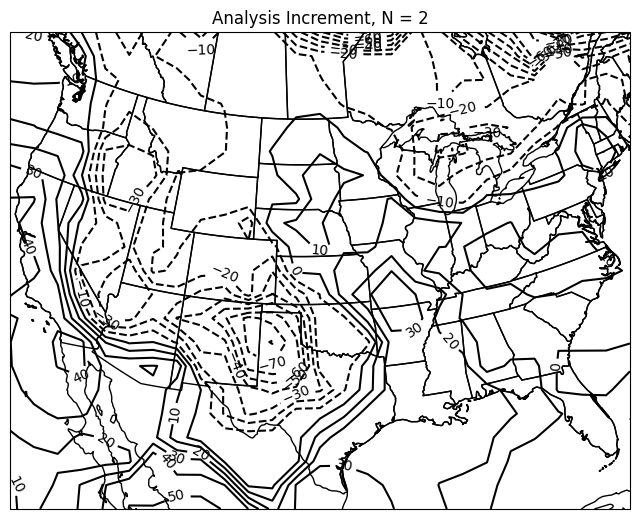

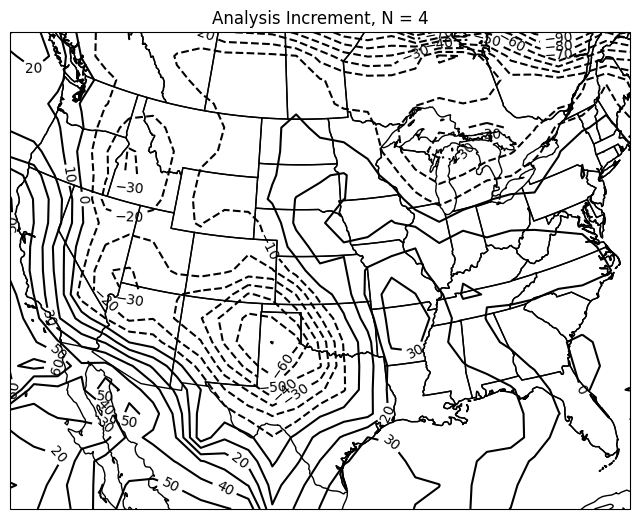

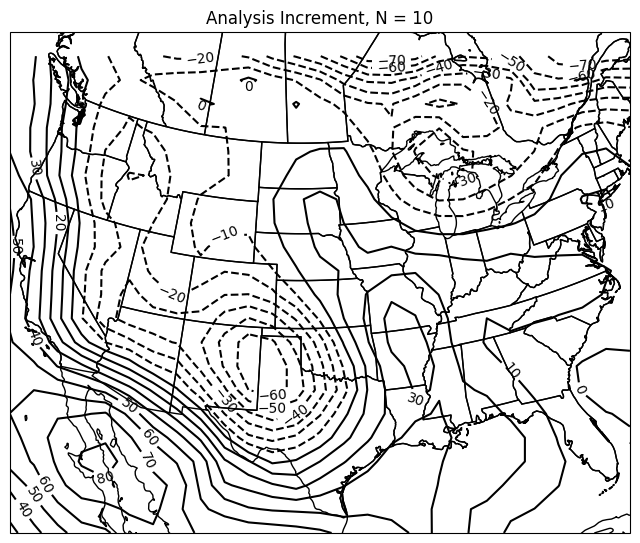

In [13]:
#plot the analysis increment fields
#increment N=2
fig=plt.figure(figsize=(8,8))
ax4=fig.add_subplot(111,projection=proj)
ax4.add_feature(cfeature.STATES)
ax4.add_feature(cfeature.COASTLINE)
cs4=ax4.contour(lon,lat,fInc[:,:,0],colors='k',levels=np.arange(-150,151,10),transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs4,levels=np.arange(-150,151,10))
ax4.set_title('Analysis Increment, N = 2')
plt.savefig('increment_N2.png')
plt.show()

#increment N=4
fig=plt.figure(figsize=(8,8))
ax5=fig.add_subplot(111,projection=proj)
ax5.add_feature(cfeature.STATES)
ax5.add_feature(cfeature.COASTLINE)
cs5=ax5.contour(lon,lat,fInc[:,:,1],colors='k',levels=np.arange(-150,151,10),transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs5,levels=np.arange(-150,151,10))
ax5.set_title('Analysis Increment, N = 4')
plt.savefig('increment_N4.png')
plt.show()

#increment N=10
fig=plt.figure(figsize=(8,8))
ax6=fig.add_subplot(111,projection=proj)
ax6.add_feature(cfeature.STATES)
ax6.add_feature(cfeature.COASTLINE)
cs6=ax6.contour(lon,lat,fInc[:,:,2],colors='k',levels=np.arange(-150,151,10),transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs6,levels=np.arange(-150,151,10))
ax6.set_title('Analysis Increment, N = 10')
plt.savefig('increment_N10.png')
plt.show()

In [14]:
#Text files analysis, increments, station differences, and RMS values

#analyses and increments (IN ONE .TXT FILE PER N VALUE)
Nnames=['N2', 'N4', 'N10']
for n, name in enumerate(Nnames):
    out=np.column_stack([np.repeat(np.arange(nx),ny),np.tile(np.arange(ny),nx),x_cm.ravel(),y_cm.ravel(),lat.ravel(),lon.ravel(),fA[:,:,n].ravel(),fInc[:,:,n].ravel()])
    fname=f'{name}.txt'
    np.savetxt(fname,out,header='i j x_cm y_cm lat lon analysis_m increment_m',fmt=['%d','%d','%.4f','%.4f','%.4f','%.4f','%.4f','%.4f'])

#analysis minus observation at each station
st_names = ['diff_N2', 'diff_N4', 'diff_N10']
for p in range(len(N_list)):
    out=np.column_stack([df['Latitude'].values,df['Longitude'].values,obs_x,obs_y,obs_z,fA_at_obs[:,p],diff_at_obs[:,p]])
    fname=f'{st_names[p]}.txt'
    np.savetxt(fname,out,header='lat lon x_cm y_cm obs_m analysis_at_obs_m analysis_minus_obs_m',fmt='%.4f')

#RMSD
out=np.column_stack([N_list,[K_N2,K_N4,K_N10],[rms_N2,rms_N4,rms_N10]])
np.savetxt('rmsd.txt',out,header='N K rms_m',fmt=['%d','%d','%.4f'])

In [15]:
### In a separte text file (or below), answer the following questions ###
'''
1 - Describe the general features that you see in your contoured analyses.
    **N=2 Analysis: There appears to be multiple kinks throughout the US. One thing I noticed was the 540dm over Idaho. Idaho appears to 
    have a distinct trough that seems almost discontinous, which goes against what we learned when we contour fields (they should be
    relatively smooth). Another thing I noticed is the trough on the west transitions to a ridge as you look towards the East coast.
    **N=4 Analysis: That troughing pattern continued to persist in the N=4 Analysis. We see that Idaho does have the trough still kinking
    abruptly. In the Gulf, the 588dm contour appears to loop around Florida, but it appears that it shoots back up in the Gulf, almost
    making it look like an error. The ridge appears to be more smooth with less kinks compared to the trough, but overall this analysis
    looks more smooth.
    **N=10 Analysis: This analysis appears to be the smoothest compared to all the other analysis maps. While the trough in Idaho has
    shifted North, the 540dm contour still seems to curve tightly leaving a corner apperance. The overall trough pattern below the Rockies
    are smoother along with the ridging pattern along the Eastern states. Additionally, the kink in the Gulf is not in this analysis,
    indicating that this analysis is more smoothed. I will like to note that in this analysis, there are minimal kinks, which helps 
    eliminate any discontinuities in the data.

    **N=2 increment: We see that the main area of positive values appeard to be where the analysis had a ridge. This indicates that the
    statistical analysis changed the background in a way that the analysis was higher than the background. Over the trough, we see that 
    values range in the negative, which is an indication that the analysis was lower than the background. We notice as we approach the
    SW coast, we see increments of 0 which indicate there was no change with the increment between the analysis and background. Areas on
    the northern boarder of the increment plot appear to be more negative, indicating analysis values are less than the background.
    **N=4 increment: We see more localized negative values near the area in Idaho as discussed in the main analysis observations and near
    the Texas panhandle. This indicates that there's more discrepancy in this area where the Analysis values came out lower than the
    background. It seemed to have become more localized than what was seen in N=2. The positive values have become more broad through 
    the eastern US where the analysis values are greater than the background. Some areas throughout the US seems to have contours that
    kink and there appears to be a smaller contour in Northern Tennessee. Same as N=2, it looks like the northern boarder of the plot
    is primarily negative values.
    **N=10: This plot looks more cohesive with the patterns we saw in the main analysis. The negative values now connect throughout the
    inner part of the trough indicating analysis values are less than the background. The positive values appear to be in the ridging
    pattern over the eastern US. The Gulf also includes these positive values. We do see on the SW that the increments eventually approach
    0 indicating there is no change between the analysis and the background. The northern boarder of the plot is still primarily 
    experiencing the same things as it was in N=2,4. There are two small 0 contours in Canada as well.
    

2 - Describe the differences that you see in your contoured analyses.  
    Does one analysis seem to be smoother than the other?  If so, what would cause this?
    **Differences between the Analysis plots: While all the plots did a great job at identifying the placement of the overall trough and
    ridge, the plots differed on smoothness. The kinks were the strongest in N=2, but we saw in N=4 that there were contours that
    appeared more sharp (like in the Gulf 588dm). In my opinion, N=10 was the smoothest and I believe this happens as the weights average
    out the localized difference between observations and background across the US compared to letting a few local stations create sharp
    features (the kinks in the N=2,4 show it the best). In N=10, information seems to be more blended over a wider area and reduces the
    noise between stations. The correlation function should ideally decay slower in N=10 when larger observation error is included to 
    keep the analysis closer to the background instead of fitting to every observation point.

    **Differences between the Increment plots: Most of the increment plots looked messy, there were areas that differed between positive
    and negative values. Even some areas that had 0 in the increment field switched to negative fields in the following plot (e.g., 
    N=2 to N=4 in the SW corner). Over the plots, the trough and ridge increments became more clear. I would say N=10 was the smoothest
    to analyze. I believe this plot was the smoothest (basing it off of the analysis discussion) due to the wider area using 10 
    observations in the analysis field. When comparing this to the background, this allowed to use a larger observation error to keep
    the analysis much closer to the Barne's analysis rather than fitting it to every observation point. This is why we see a more 
    uniformed increment field compared to the mess of +/- increments throughout the US.
    
3 - What happens as you increase the number of points considered for the analysis?  Is this 
    desirable?  Why or why not?
    Increasing the number of closest stations in the analysis at each gridpoint will include from a broader area of observations, which
    would typically produce smoother analysis and increment fields, reducing the sharp kinks in the data field, and decreasing RMSD 
    differences at observation stations. This can be desirable because it reduces station noise, avoids depending on a few stations,
    and creates cleaner patters... BUT this can also be undesirable if N is increased too much due to distant/weak correlated stations
    identify unrealistic regional features for the analysis. This could over smooth smaller-scale features and increase computational
    cost due to a potentially large weight at each grid point. This could also impact the correlation matrix when closely spaced stations
    have a high correlation.
'''

"\n1 - Describe the general features that you see in your contoured analyses.\n    **N=2 Analysis: There appears to be multiple kinks throughout the US. One thing I noticed was the 540dm over Idaho. Idaho appears to \n    have a distinct trough that seems almost discontinous, which goes against what we learned when we contour fields (they should be\n    relatively smooth). Another thing I noticed is the trough on the west transitions to a ridge as you look towards the East coast.\n    **N=4 Analysis: That troughing pattern continued to persist in the N=4 Analysis. We see that Idaho does have the trough still kinking\n    abruptly. In the Gulf, the 588dm contour appears to loop around Florida, but it appears that it shoots back up in the Gulf, almost\n    making it look like an error. The ridge appears to be more smooth with less kinks compared to the trough, but overall this analysis\n    looks more smooth.\n    **N=10 Analysis: This analysis appears to be the smoothest compared to all